# **Parte 4: TURF y Clustering**

8. TURF Analysis:
    - Elige al menos 5 variables que representen elecciones dicotómicas (sí/no) - dicotomizar en caso necesario.
    - Justifica tu elección.
    - Ejecuta el análisis para encontrar la mejor combinación que maximice cobertura.
    - **Justifica tu recomendación con visualizaciones y análisis.**

9. K-Means Clustering:
    - Selecciona 5 variables para agrupar.
    - Escala las variables si es necesario.
    - Ejecuta el algoritmo para al menos dos valores de k.
    - Usa el gráfico del codo para justificar k.
    - **Describe los grupos resultantes con base en las variables seleccionadas.**

10. Clustering Jerárquico:
    - Aplica métodos single, complete y average.
    - Muestra los dendrogramas.
    - Elige el número de grupos y justifica tu decisión.
    - **Describe cada grupo de forma clara.**

**Compara los dos métodos de clustering (Kmeans vs Jerárquico).**

### **0: Dependencias**

In [1]:
import os
import itertools

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Carpeta donde se guardan las figuras (se reutilizan en el reporte en PDF)
FIG_DIR = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Tarea/Documentos/Practica_4/figures/"
os.makedirs(FIG_DIR, exist_ok=True)

##### Carga del dataset limpio

In [2]:
# Mismo dataset limpio de las prácticas anteriores (sin duplicados y con NAs/outliers tratados)
path = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Practicas/Netflix_clean.csv"
df = pd.read_csv(path)

print(f"El dataset tiene {df.shape[0]:,} observaciones y {df.shape[1]} variables.")
df.head(1)

El dataset tiene 15,330 observaciones y 31 variables.


,Title,Genre,Tags,Languages,Series or Movie,Hidden Gem Score,Country Availability,Runtime,Director,Writer,...,Netflix Link,IMDb Link,Summary,IMDb Votes,Image,Poster,TMDb Trailer,Trailer Site,IMDb Votes_log,Boxoffice_log
0,Lets Fight Ghost,"Crime, Drama, Fantasy, Horror, Romance","Comedy Programmes,Romantic TV Comedies,Horror ...","Swedish, Spanish",Series,4.3,Thailand,< 30 minutes,Tomas Alfredson,John Ajvide Lindqvist,...,https://www.netflix.com/watch/81415947,https://www.imdb.com/title/tt1139797,A med student with a supernatural gift tries t...,205926.0,https://occ-0-4708-64.1.nflxso.net/dnm/api/v6/...,https://m.media-amazon.com/images/M/MV5BOWM4NT...,NaN,NaN,12.235277,14.567901


### **8. TURF Analysis**

##### 8.1: Elección de las variables dicotómicas

In [3]:
# Cada género es una variable sí/no: el título lo tiene o no. Se toman los 12 con más títulos
GENEROS = ["Drama", "Comedy", "Action", "Thriller", "Romance", "Crime", "Adventure",
           "Animation", "Documentary", "Horror", "Family", "Fantasy"]

generos = df["Genre"].fillna("").str.get_dummies(sep=", ").astype(bool)
G = generos[GENEROS]
ORDEN = G.sum().sort_values(ascending=False).index.tolist()      # de más a menos títulos

sin_genero = ~generos.any(axis=1)
print(f"Títulos sin ningún género: {sin_genero.sum():,} ({sin_genero.mean():.1%}). Techo de alcance con todos los géneros: {generos.any(axis=1).mean():.1%}")
pd.DataFrame({"Títulos": G.sum(), "% del catálogo": (G.mean() * 100).round(1)}).loc[ORDEN].T

Títulos sin ningún género: 1,708 (11.1%). Techo de alcance con todos los géneros: 88.9%


,Drama,Comedy,Action,Thriller,Romance,Crime,Adventure,Animation,Fantasy,Family,Horror,Documentary
Títulos,6273.0,5030.0,2768.0,2690.0,2409.0,1901.0,1790.0,1645.0,1567.0,1417.0,1052.0,1029.0
% del catálogo,40.9,32.8,18.1,17.5,15.7,12.4,11.7,10.7,10.2,9.2,6.9,6.7


- Se usan los 12 géneros con más títulos (todos pasan de 1,000). Un género ya es una elección sí/no, así que no hace falta ningún umbral.
- Hay solapamiento real entre ellos (un título puede ser Drama y Romance a la vez), y eso es justo lo que TURF aprovecha: no basta con tomar los géneros más grandes, hay que ver cuáles suman títulos nuevos.
- Los 1,708 títulos sin género nunca se alcanzan, así que el alcance máximo posible es 88.9%.

##### 8.2: Búsqueda de la mejor combinación

In [4]:
def alcance(cols):
    """Proporción de títulos que tienen al menos uno de los géneros elegidos."""
    return G[list(cols)].any(axis=1).mean()

def frecuencia(cols):
    """Promedio de géneros elegidos que tiene cada título alcanzado."""
    n = G[list(cols)].sum(axis=1)
    return n[n > 0].mean()

# Búsqueda exhaustiva: se prueban todas las combinaciones de k géneros (k = 1..7) de los 12
filas, previo = [], 0
for k in range(1, 8):
    turf = max(itertools.combinations(GENEROS, k), key=alcance)
    ingenuo = tuple(ORDEN[:k])                                    # los k géneros con más títulos
    filas.append({"k": k, "Combinación TURF": turf, "Alcance TURF": alcance(turf), "Ganancia": alcance(turf) - previo,
                  "Frecuencia": frecuencia(turf), "Los k más grandes": ingenuo, "Alcance ingenuo": alcance(ingenuo)})
    previo = alcance(turf)
res = pd.DataFrame(filas).set_index("k")

tabla = res.copy()
tabla["Combinación TURF"] = tabla["Combinación TURF"].map(", ".join)
tabla["Los k más grandes"] = tabla["Los k más grandes"].map(", ".join)
for c in ["Alcance TURF", "Ganancia", "Alcance ingenuo"]:
    tabla[c] = (tabla[c] * 100).round(1)
tabla["Frecuencia"] = tabla["Frecuencia"].round(2)
tabla

,Combinación TURF,Alcance TURF,Ganancia,Frecuencia,Los k más grandes,Alcance ingenuo
k,,,,,,
1,Drama,40.9,40.9,1.00,Drama,40.9
2,"Drama, Comedy",63.6,22.7,1.16,"Drama, Comedy",63.6
3,"Drama, Comedy, Action",71.3,7.7,1.29,"Drama, Comedy, Action",71.3
4,"Drama, Comedy, Action, Documentary",77.0,5.7,1.28,"Drama, Comedy, Action, Thriller",74.7
5,"Drama, Comedy, Action, Thriller, Documentary",80.4,3.5,1.44,"Drama, Comedy, Action, Thriller, Romance",75.8
6,"Drama, Comedy, Action, Thriller, Animation, Do...",83.0,2.5,1.53,"Drama, Comedy, Action, Thriller, Romance, Crime",76.6
7,"Drama, Comedy, Action, Thriller, Animation, Do...",84.2,1.2,1.59,"Drama, Comedy, Action, Thriller, Romance, Crim...",77.7


In [5]:
# Las 5 mejores combinaciones de 5 géneros
top5 = sorted(itertools.combinations(GENEROS, 5), key=alcance, reverse=True)[:5]
pd.DataFrame({"Combinación": [", ".join(c) for c in top5], "Alcance (%)": [round(alcance(c) * 100, 1) for c in top5]})

,Combinación,Alcance (%)
0,"Drama, Comedy, Action, Thriller, Documentary",80.4
1,"Drama, Comedy, Thriller, Animation, Documentary",80.3
2,"Drama, Comedy, Action, Documentary, Horror",79.9
3,"Drama, Comedy, Action, Animation, Documentary",79.6
4,"Drama, Comedy, Thriller, Adventure, Documentary",79.5


- **Con 5 géneros, la mejor combinación es Drama, Comedy, Action, Thriller y Documentary: alcanza 80.4% de los títulos** (90% del máximo posible de 88.9%), con 1.44 géneros por título alcanzado.
- Tomar simplemente los 5 géneros más grandes (cambiar Documentary por Romance) se queda en 75.8%. Desde el cuarto género TURF y el ranking ingenuo se separan.
- La segunda mejor combinación (cambia Action por Animation) queda a solo 0.1 puntos, así que hay cierta flexibilidad en el último género.

##### 8.3: Visualizaciones

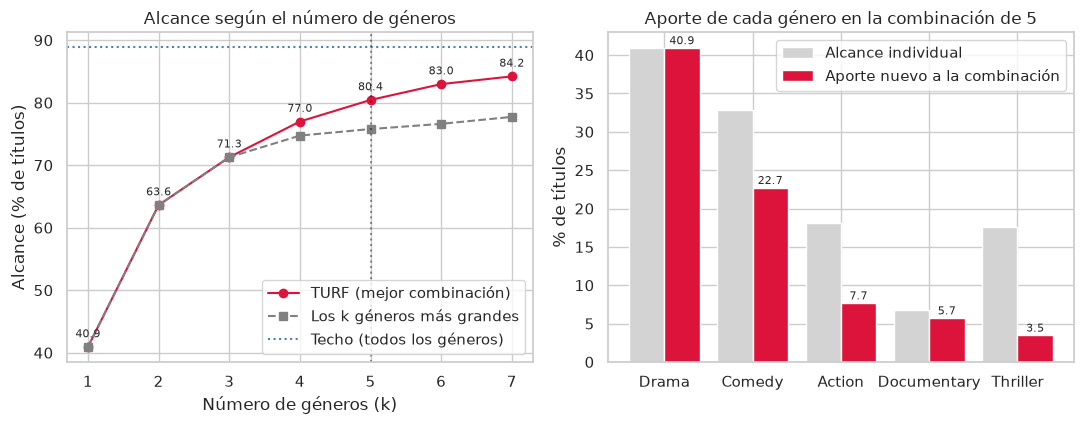

,Género,Aporte nuevo (pts),Alcance individual (%)
0,Drama,40.9,40.9
1,Comedy,22.7,32.8
2,Action,7.7,18.1
3,Documentary,5.7,6.7
4,Thriller,3.5,17.5


In [6]:
K_TURF = 5
mejor = list(res.loc[K_TURF, "Combinación TURF"])

# Aporte de cada género de la combinación, en el orden en que más títulos nuevos suma
cubierto = np.zeros(len(G), dtype=bool)
aportes, restantes = [], mejor.copy()
while restantes:
    g = max(restantes, key=lambda c: (G[c].values & ~cubierto).sum())
    aportes.append((g, (G[g].values & ~cubierto).mean() * 100, G[g].mean() * 100))
    cubierto |= G[g].values
    restantes.remove(g)
aporte = pd.DataFrame(aportes, columns=["Género", "Aporte nuevo (pts)", "Alcance individual (%)"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(res.index, res["Alcance TURF"] * 100, "o-", color="crimson", label="TURF (mejor combinación)")
ax[0].plot(res.index, res["Alcance ingenuo"] * 100, "s--", color="gray", label="Los k géneros más grandes")
ax[0].axhline(generos.any(axis=1).mean() * 100, color="steelblue", ls=":", label="Techo (todos los géneros)")
ax[0].axvline(K_TURF, color="black", ls=":", alpha=.4)
for k, v in res["Alcance TURF"].items():
    ax[0].annotate(f"{v*100:.1f}", (k, v * 100), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax[0].set(xlabel="Número de géneros (k)", ylabel="Alcance (% de títulos)", title="Alcance según el número de géneros")
ax[0].legend(loc="lower right")

x = np.arange(len(aporte))
ax[1].bar(x - .2, aporte["Alcance individual (%)"], .4, color="lightgray", label="Alcance individual")
ax[1].bar(x + .2, aporte["Aporte nuevo (pts)"], .4, color="crimson", label="Aporte nuevo a la combinación")
ax[1].set_xticks(x, aporte["Género"])
for i, v in enumerate(aporte["Aporte nuevo (pts)"]):
    ax[1].text(i + .2, v + .5, f"{v:.1f}", ha="center", fontsize=8)
ax[1].set(ylabel="% de títulos", title=f"Aporte de cada género en la combinación de {K_TURF}")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_8_turf_alcance.png", dpi=150)
plt.show()
aporte.round(1)

- Las ganancias caen rápido: Drama y Comedy suman 63.6%, Action agrega 7.7 puntos, Documentary 5.7, Thriller 3.5, y de ahí en adelante son 2.5 y 1.2 puntos por género. Se recomienda **k = 5**: el sexto género ya da menos de 3 puntos.
- Documentary tiene solo 6.7% de alcance individual, pero casi no se cruza con nada (Jaccard de 0.03 o menos), así que 5.7 puntos son títulos nuevos. Thriller es lo contrario: llega a 17.5% solo, pero se solapa con Drama, Action y Crime y aporta 3.5.
- Romance (15.7%) se queda fuera porque se solapa con Drama y Comedy (Jaccard 0.21 y 0.20).

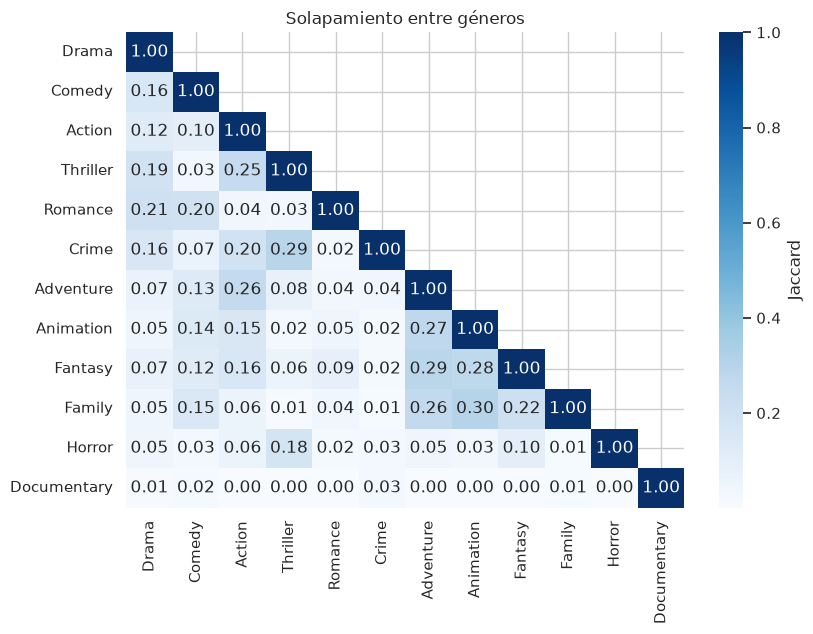

In [7]:
# Solapamiento entre géneros (Jaccard: títulos en común / títulos en alguno de los dos)
M = G.values.astype(int)
inter = M.T @ M
union = M.sum(0)[:, None] + M.sum(0)[None, :] - inter
jac = pd.DataFrame(inter / union, index=GENEROS, columns=GENEROS).loc[ORDEN, ORDEN]

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Blues", mask=np.triu(np.ones_like(jac, dtype=bool), k=1), cbar_kws={"label": "Jaccard"})
plt.title("Solapamiento entre géneros")
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_8_turf_solape.png", dpi=150)
plt.show()

Los pares que más se solapan son Crime-Thriller (0.29), Family-Animation (0.30) y Adventure-Fantasy (0.29), por eso TURF no los junta en una misma combinación.

### **9. K-Means Clustering**

##### 9.1: Variables y escalado

In [8]:
X = pd.DataFrame({
    "IMDb Score": df["IMDb Score"],
    "IMDb Votes (log)": df["IMDb Votes_log"],
    "N° géneros": generos.sum(axis=1),
    "N° países": df["Country Availability"].fillna("").str.split(",").map(lambda l: len([p for p in l if p.strip()])),
    "Año en Netflix": pd.to_datetime(df["Netflix Release Date"]).dt.year,
})
VARS = X.columns.tolist()

Z = StandardScaler().fit_transform(X)       # media 0 y desviación 1: sin escalar mandarían los países (0 a 36) y el año
print(X.isna().sum().sum(), "valores faltantes")
display(X.describe().T.round(2))
X.corr().round(2)

0 valores faltantes


,count,mean,std,min,25%,50%,75%,max
IMDb Score,15330.0,6.49,1.07,1.00,6.0,6.50,7.20,9.70
IMDb Votes (log),15330.0,8.29,2.65,1.79,6.3,8.29,10.66,14.67
N° géneros,15330.0,2.30,1.56,0.00,1.0,2.00,3.00,12.00
N° países,15330.0,12.64,14.05,0.00,1.0,4.00,28.00,36.00
Año en Netflix,15330.0,2017.88,1.96,2015.00,2016.0,2018.00,2020.00,2021.00


,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
IMDb Score,1.00,0.20,0.08,0.07,-0.10
IMDb Votes (log),0.20,1.00,0.08,-0.07,-0.29
N° géneros,0.08,0.08,1.00,0.01,-0.26
N° países,0.07,-0.07,0.01,1.00,0.06
Año en Netflix,-0.10,-0.29,-0.26,0.06,1.00


- Se agrupan los títulos con `IMDb Score`, `IMDb Votes (log)`, `N° géneros`, `N° países` (países donde está disponible) y `Año en Netflix` (año en que llegó). Cubren calidad, popularidad, amplitud del catálogo y antigüedad, y no tienen faltantes.
- Se dejó fuera `Hidden Gem Score` porque correlaciona -0.79 con los votos y contaría dos veces lo mismo. Las cinco elegidas casi no se correlacionan entre sí (el máximo es 0.29 en valor absoluto).
- Las variables están en escalas muy distintas (países de 0 a 36, año de 2015 a 2021), así que se estandarizan antes de agrupar.

##### 9.2: Gráfico del codo

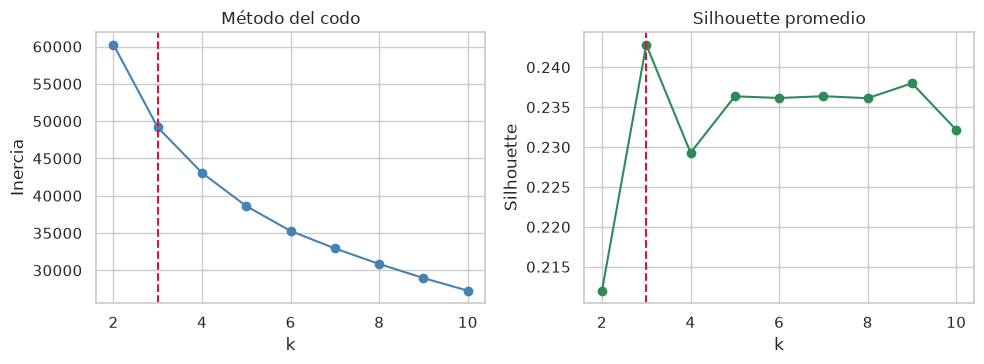

,2,3,4,5,6,7,8,9,10
Inercia,60258.0,49163.0,43060.0,38604.0,35269.0,32935.0,30845.0,28961.0,27269.0
Caída,-,11094.0,6103.0,4456.0,3335.0,2334.0,2090.0,1884.0,1691.0
Silhouette,0.212,0.243,0.229,0.236,0.236,0.236,0.236,0.238,0.232


In [9]:
KS = range(2, 11)
inercia, sil = [], []
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

K = 3
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(KS, inercia, "o-", color="steelblue")
ax[0].axvline(K, color="crimson", ls="--")
ax[0].set(xlabel="k", ylabel="Inercia", title="Método del codo")
ax[1].plot(KS, sil, "o-", color="seagreen")
ax[1].axvline(K, color="crimson", ls="--")
ax[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette promedio")
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_9_codo.png", dpi=150)
plt.show()
pd.DataFrame({"Inercia": np.round(inercia), "Caída": ["-"] + list(np.round(-np.diff(inercia))), "Silhouette": np.round(sil, 3)}, index=list(KS)).T

- La inercia baja sin un codo marcado, pero la caída se corta después de k = 3: de 2 a 3 grupos baja 11,094 y de 3 a 4 baja 6,103; de ahí en adelante cada grupo extra resta menos.
- El silhouette tiene su máximo en **k = 3** (0.243). Es un valor bajo: los grupos se tocan en el espacio de las variables (se ve en el PCA), así que son segmentos de tendencia y no grupos separados.
- Se ejecuta con k = 3 y con k = 5, que tiene un Davies-Bouldin menor (1.35 contra 1.52) y da más detalle.

##### 9.3: Ejecución con k = 3 y k = 5

In [10]:
def perfil(etiquetas):
    """Tamaño y medias originales de cada grupo."""
    t = X.groupby(etiquetas).mean().round(2)
    t.insert(0, "Títulos", pd.Series(etiquetas).value_counts().sort_index().values)
    t.insert(1, "%", (t["Títulos"] / len(X) * 100).round(1))
    return t

km = {k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z) for k in (3, 5)}
met = pd.DataFrame({f"k = {k}": {"Inercia": m.inertia_, "Silhouette": silhouette_score(Z, m.labels_),
                                  "Davies-Bouldin": davies_bouldin_score(Z, m.labels_),
                                  "Calinski-Harabasz": calinski_harabasz_score(Z, m.labels_)} for k, m in km.items()})
display(met.round(3))
for k in (3, 5):
    print(f"\nK-Means, k = {k}")
    display(perfil(km[k].labels_))

,k = 3,k = 5
Inercia,49163.101,38604.431
Silhouette,0.243,0.236
Davies-Bouldin,1.516,1.352
Calinski-Harabasz,4284.638,3775.791



K-Means, k = 3


,Títulos,%,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
0,6234,40.7,6.20,7.41,1.64,3.34,2019.11
1,4157,27.1,6.57,7.48,2.10,33.02,2018.43
2,4939,32.2,6.80,10.07,3.30,7.23,2015.88



K-Means, k = 5


,Títulos,%,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
0,2073,13.5,4.69,6.32,2.09,9.14,2018.26
1,3382,22.1,6.85,6.04,2.37,3.58,2018.83
2,4028,26.3,6.84,10.45,3.39,7.72,2015.65
3,3609,23.5,6.77,7.69,2.15,33.92,2018.44
4,2238,14.6,6.56,10.57,0.67,4.14,2019.22


Con k = 3, la partición se reparte en 40.7%, 27.1% y 32.2% de los títulos. Con k = 5 los tamaños van de 13.5% a 26.3%.

Varianza explicada por los 2 componentes: [0.305 0.212] → 0.517
                   PC1   PC2
IMDb Score       -0.38  0.51
IMDb Votes (log) -0.55 -0.07
N° géneros       -0.44  0.03
N° países         0.09  0.84
Año en Netflix    0.60  0.16


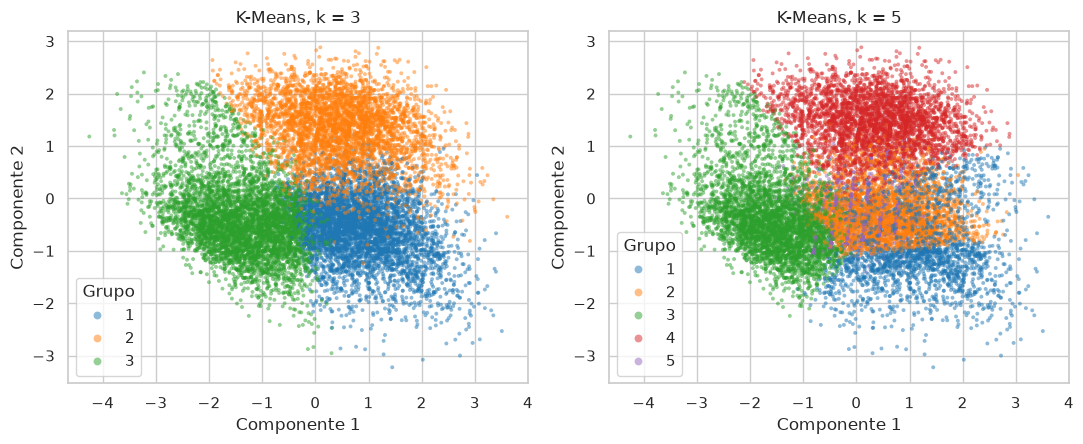

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
P = pca.transform(Z)
print("Varianza explicada por los 2 componentes:", pca.explained_variance_ratio_.round(3), "→", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=VARS, columns=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, k in zip(ax, (3, 5)):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=km[k].labels_ + 1, palette="tab10", s=8, alpha=.5, linewidth=0, ax=a)
    a.set(xlabel="Componente 1", ylabel="Componente 2", title=f"K-Means, k = {k}")
    a.legend(title="Grupo", markerscale=2)
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_9_pca.png", dpi=150)
plt.show()

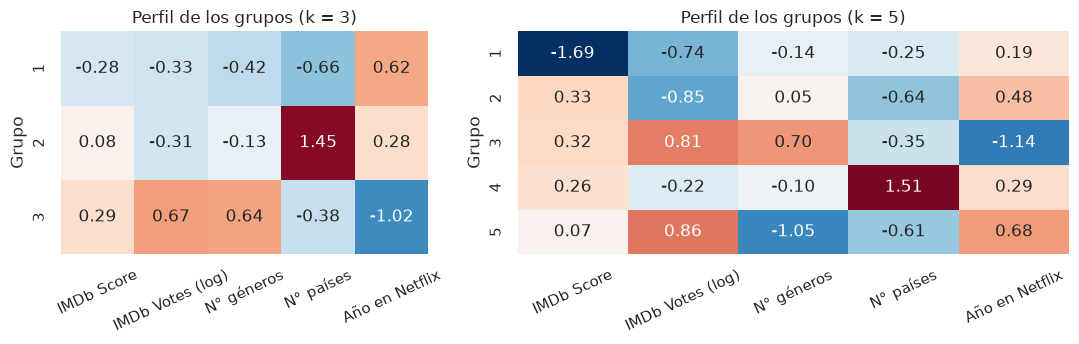

In [12]:
# Perfil estandarizado de los grupos (0 = promedio del catálogo)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
for a, k in zip(ax, (3, 5)):
    prof = pd.DataFrame(Z, columns=VARS).groupby(km[k].labels_ + 1).mean()
    sns.heatmap(prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.6, vmax=1.6, cbar=False, ax=a)
    a.set(xlabel="", ylabel="Grupo", title=f"Perfil de los grupos (k = {k})")
    a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_9_perfil.png", dpi=150)
plt.show()

**Grupos con k = 3** (el PCA explica 51.7% de la variabilidad; el componente 2 es sobre todo el número de países y el 1, el año y los votos):
1. **Recientes y de poca difusión (40.7%).** Llegaron en 2019 en promedio, están en pocos países (3.3), tienen pocos votos (unos 1,700) y 1.6 géneros. Son los de calificación más baja (6.20).
2. **Catálogo global (27.1%).** Están disponibles en 33 países en promedio (el resto, entre 3 y 7), con calificación media (6.57), pocos votos y 2.1 géneros.
3. **Establecidos y populares (32.2%).** Llegaron antes (2015.9), tienen muchos votos (unos 24,000), 3.3 géneros y la mejor calificación (6.80).

**Con k = 5** se separan los títulos de calificación muy baja (4.69 de promedio, 13.5%), los de buena calificación pero pocos votos (6.85, 22.1%) y los que casi no tienen géneros registrados (0.67 en promedio, 14.6%, con muchos votos). El grupo global (4) y el de establecidos (3) se mantienen.

### **10. Clustering Jerárquico**

##### 10.1: Métodos single, complete y average

In [13]:
D = pdist(Z)                                  # distancias euclidianas entre los 15,330 títulos
METODOS = ["single", "complete", "average"]
L = {m: linkage(D, m) for m in METODOS}
coef = {m: cophenet(L[m], D)[0] for m in METODOS}
print({m: round(c, 3) for m, c in coef.items()}, "← correlación cofenética")

{'single': np.float64(0.361), 'complete': np.float64(0.346), 'average': np.float64(0.58)} ← correlación cofenética


Se usan los 15,330 títulos completos, con distancia euclidiana sobre las mismas variables estandarizadas. La correlación cofenética (qué tanto el árbol conserva las distancias originales) es baja en single y complete (0.36 y 0.35) y mejor en average (0.58).

##### 10.2: Dendrogramas

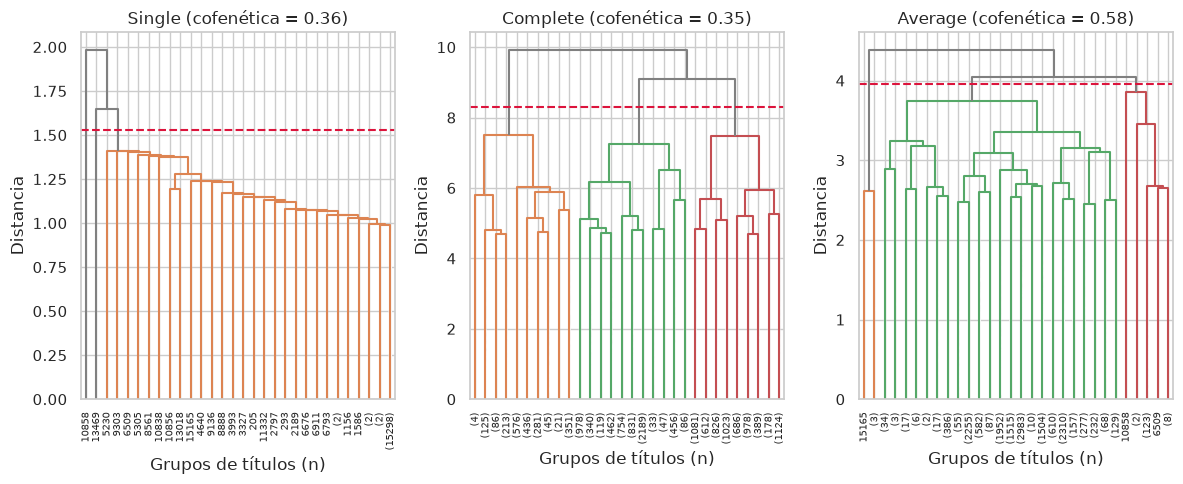

In [14]:
K_J = 3
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
for a, m in zip(ax, METODOS):
    corte = (L[m][-K_J, 2] + L[m][-K_J + 1, 2]) / 2         # altura que deja K_J grupos
    dendrogram(L[m], truncate_mode="lastp", p=30, ax=a, leaf_rotation=90, leaf_font_size=7,
               show_contracted=True, color_threshold=corte, above_threshold_color="gray")
    a.axhline(corte, color="crimson", ls="--")
    a.set(title=f"{m.capitalize()} (cofenética = {coef[m]:.2f})", xlabel="Grupos de títulos (n)", ylabel="Distancia")
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_10_dendrogramas.png", dpi=150)
plt.show()

- **Single** encadena: va pegando títulos uno por uno a un grupo enorme, y las uniones nunca pasan de 2.0. Los dos grupos que se separan arriba son un título solo cada uno.
- **Average** se comporta parecido: separa 4 títulos y luego 135, y el resto es un solo bloque.
- **Complete** es el único que forma ramas parejas: a la altura marcada se separan tres bloques de tamaño comparable.

##### 10.3: Número de grupos

In [15]:
# Alturas de las últimas 8 uniones: un salto grande indica que se están juntando grupos muy distintos
alt = pd.DataFrame({m: L[m][-8:, 2][::-1] for m in METODOS}, index=[f"{i}→{i-1} grupos" for i in range(2, 10)]).round(2)
display(alt)
display(alt.diff().abs().iloc[1:].round(2).rename(columns=lambda c: f"Salto {c}"))

,single,complete,average
2→1 grupos,1.98,9.92,4.39
3→2 grupos,1.65,9.09,4.05
4→3 grupos,1.41,7.50,3.86
5→4 grupos,1.41,7.47,3.74
6→5 grupos,1.40,7.26,3.46
7→6 grupos,1.38,6.50,3.36
8→7 grupos,1.38,6.16,3.24
9→8 grupos,1.38,6.02,3.18


,Salto single,Salto complete,Salto average
3→2 grupos,0.33,0.83,0.34
4→3 grupos,0.24,1.59,0.19
5→4 grupos,0.00,0.03,0.12
6→5 grupos,0.01,0.21,0.28
7→6 grupos,0.02,0.76,0.10
8→7 grupos,0.00,0.34,0.12
9→8 grupos,0.00,0.14,0.06


Se eligen **3 grupos**. En complete el mayor salto de altura (1.59) es entre la unión de 4 a 3 grupos (7.50) y la de 3 a 2 (9.09), así que cortar en 3 deja los grupos lo más separados posible. Para single y average también se usa k = 3 para poder compararlos con el mismo número de grupos que K-Means, aunque ahí el salto no es tan claro.

##### 10.4: Descripción de los grupos

In [16]:
gj = {m: fcluster(L[m], K_J, "maxclust") for m in METODOS}
for m in METODOS:
    print(f"\n{m.capitalize()}, k = {K_J}")
    display(perfil(gj[m]))


Single, k = 3


,Títulos,%,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
1,15328,100.0,6.49,8.29,2.3,12.64,2017.88
2,1,0.0,1.70,8.98,2.0,35.00,2015.00
3,1,0.0,8.20,10.16,12.0,19.00,2016.00



Complete, k = 3


,Títulos,%,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
1,2138,13.9,6.50,8.33,4.60,10.79,2017.73
2,6295,41.1,5.76,8.74,1.55,12.93,2017.96
3,6897,45.0,7.16,7.86,2.27,12.96,2017.86



Average, k = 3


,Títulos,%,IMDb Score,IMDb Votes (log),N° géneros,N° países,Año en Netflix
1,4,0.0,8.75,2.28,3.50,35.25,2016.50
2,15191,99.1,6.48,8.28,2.26,12.71,2017.90
3,135,0.9,7.40,8.90,6.79,4.14,2015.91


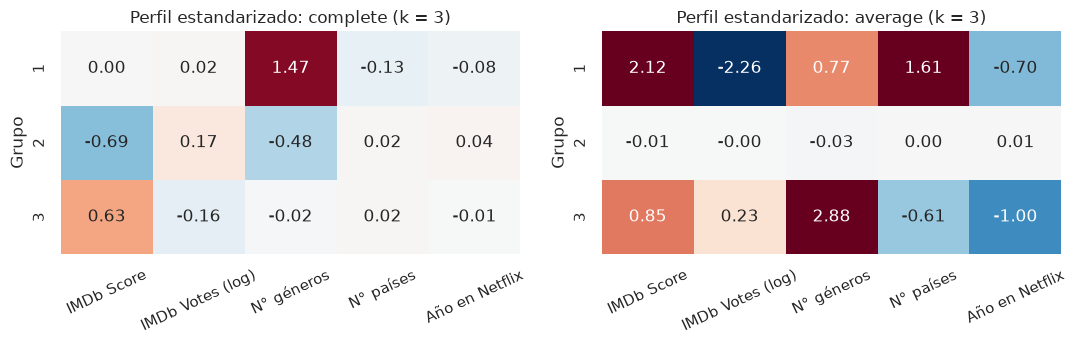

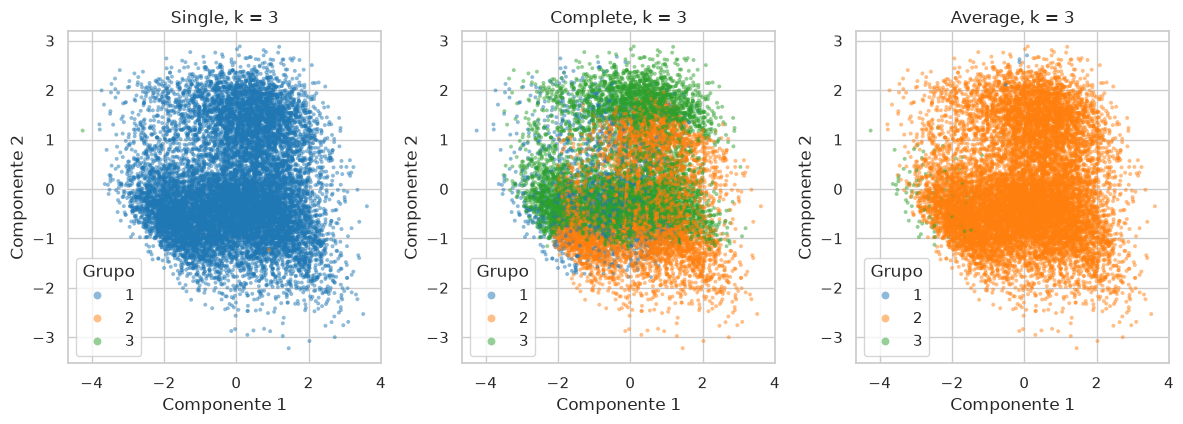

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1]})
for a, m in zip(ax, ["complete", "average"]):
    prof = pd.DataFrame(Z, columns=VARS).groupby(gj[m]).mean()
    sns.heatmap(prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.6, vmax=1.6, cbar=False, ax=a)
    a.set(xlabel="", ylabel="Grupo", title=f"Perfil estandarizado: {m} (k = {K_J})")
    a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_10_perfil.png", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
for a, m in zip(ax, METODOS):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=gj[m], palette="tab10", s=8, alpha=.5, linewidth=0, ax=a)
    a.set(xlabel="Componente 1", ylabel="Componente 2", title=f"{m.capitalize()}, k = {K_J}")
    a.legend(title="Grupo", markerscale=2)
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_10_pca.png", dpi=150)
plt.show()

**Complete, k = 3** (el único con grupos de tamaño razonable; separa sobre todo por calificación y número de géneros):
1. **Multigénero (13.9%, 2,138 títulos).** 4.6 géneros en promedio, con calificación promedio (6.50).
2. **Calificación baja y pocos géneros (41.1%, 6,295 títulos).** IMDb Score de 5.76 y 1.55 géneros.
3. **Calificación alta (45.0%, 6,897 títulos).** IMDb Score de 7.16 y 2.3 géneros.
En país y año los tres grupos son casi iguales al promedio.

**Single, k = 3:** un grupo con 15,328 títulos (casi todo) y dos títulos aislados: uno con calificación de 1.7 disponible en 35 países y otro con 12 géneros.

**Average, k = 3:** un grupo con 15,191 títulos (99.1%), otro de 135 títulos con muchos géneros (6.8 en promedio, pocos países y llegada hacia 2016) y uno de 4 títulos con calificación de 8.75, pocos votos (unos 10) y disponibles en 35 países. Son valores atípicos más que grupos.

### **Comparación: K-Means vs. Jerárquico**

In [18]:
etq = {"K-Means": km[3].labels_ + 1, **{f"Jerárquico {m}": gj[m] for m in METODOS}}
filas = {}
for nombre, e in etq.items():
    tam = np.bincount(e)[1:]
    filas[nombre] = {"Grupos": len(tam), "Grupo más grande (%)": tam.max() / len(e) * 100, "Grupo más chico (títulos)": tam.min(),
                     "Silhouette": silhouette_score(Z, e), "Davies-Bouldin": davies_bouldin_score(Z, e),
                     "Calinski-Harabasz": calinski_harabasz_score(Z, e),
                     "ARI vs. K-Means": adjusted_rand_score(etq["K-Means"], e)}
comp = pd.DataFrame(filas).T
comp.round(3)

,Grupos,Grupo más grande (%),Grupo más chico (títulos),Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs. K-Means
K-Means,3.0,40.665,4157.0,0.243,1.516,4284.638,1.000
Jerárquico single,3.0,99.987,1.0,0.409,0.398,6.790,0.000
Jerárquico complete,3.0,44.990,2138.0,0.081,2.655,1448.002,0.018
Jerárquico average,3.0,99.093,4.0,0.179,1.016,150.391,0.001


- **K-Means (k = 3)** reparte el catálogo en tres grupos de 27% a 41%. **Complete** también (14% a 45%), pero con una cohesión mucho peor: silhouette de 0.081 contra 0.243, y Calinski-Harabasz de 1,448 contra 4,285.
- **Single y average** forman un solo grupo con más de 99% de los títulos. Su silhouette de 0.409 (single) y 0.179 (average) engaña: sale alto porque unos pocos títulos aislados quedan muy lejos de todo. Con un grupo de 99.99% la partición no segmenta nada.
- Las particiones casi no se parecen: el ARI de K-Means contra complete es 0.018, o sea, cada método está encontrando una estructura distinta (K-Means separa por países y año de llegada; complete, por calificación y géneros).

K-Means (filas) vs. Jerárquico complete (columnas)


complete,1,2,3
K-Means,,,
1,615,3034,2585
2,399,1798,1960
3,1124,1463,2352


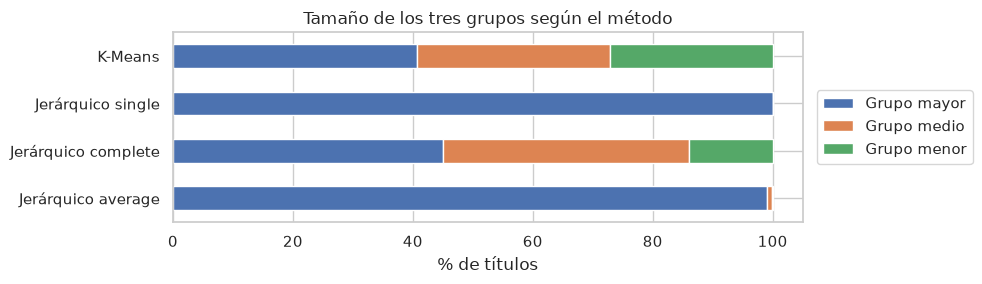

In [19]:
print("K-Means (filas) vs. Jerárquico complete (columnas)")
display(pd.crosstab(etq["K-Means"], etq["Jerárquico complete"], rownames=["K-Means"], colnames=["complete"]))

fig, ax = plt.subplots(figsize=(10, 3))
prop = pd.DataFrame({n: np.sort(np.bincount(e)[1:])[::-1] / len(e) * 100 for n, e in etq.items()}).T
prop.columns = ["Grupo mayor", "Grupo medio", "Grupo menor"]
prop.plot.barh(stacked=True, ax=ax, color=["#4c72b0", "#dd8452", "#55a868"])
ax.invert_yaxis()
ax.set(xlabel="% de títulos", title="Tamaño de los tres grupos según el método")
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5))
plt.tight_layout()
plt.savefig(FIG_DIR + "p4_c_tamanos.png", dpi=150)
plt.show()

**K-Means es el método recomendado:** grupos balanceados, mejores métricas de cohesión (silhouette, Davies-Bouldin 1.52 y Calinski-Harabasz) con un número comparable de grupos, y una lectura clara. Complete queda como alternativa si interesa segmentar por calificación y géneros, y single y average se descartan por el encadenamiento. Aun así, con silhouette de 0.24 el catálogo no tiene grupos naturales bien separados: los tres grupos de K-Means son tendencias más que clases.